In [1]:
import rdkit
import pandas as pd
from validation import *
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import numpy as np
import seaborn
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import ipywidgets
import warnings
import scipy.stats as stats
from rdkit.Contrib.SA_Score import sascorer

In [2]:
warnings.filterwarnings('ignore', category=UserWarning, module='umap')
warnings.filterwarnings('ignore', category=UserWarning, module='pynndescent')

# Paths

In [3]:
path_smiles_task1 = '../csv_llms_task_1'
path_smiles_task2 = '../csv_llms_task_2'

# Lists

In [4]:
lst_quants = ['BF16', 'Q8', 'Q6', 'Q4']
lst_models = ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
lst_models_labels = ['Mistral4', 'Qwen3.6', 'Gemma4', 'GPT-OSS']
lst_replicas = range(1,20+1)

In [5]:
pval = 0.05

# **Functions**

In [6]:
def pos_boxplot(box_width = 0.15, group_spacing = 1.0):
    d_pos_hboxplot = {}

    for i_quant, q in enumerate(lst_quants):
        for i_model, m in enumerate(lst_models):
            if m not in d_pos_hboxplot:
                d_pos_hboxplot[m] = {}
            d_pos_hboxplot[m][q] = (i_model * group_spacing) + (i_quant * box_width)

    return d_pos_hboxplot

def pos_barplot():
    d_pos = {}

    for m in lst_models:
        d_pos[m] = {}
        for q in lst_quants:
            d_pos[m][q] = x
            x+=1
        x+=1
    return d_pos

def pos_barplot():
    d_pos = {}
    x=0
    for m in lst_models:
        d_pos[m] = {}
        for q in lst_quants:
            d_pos[m][q] = x
            x+=1
        x+=1
    return d_pos

def annonate_hboxplot(ax, df, col, pval, x):
    df_pvals = utest_intramodel(df=df, col=col, pval_threshold=pval)
    lst = df_pvals.index.values.tolist()
    if len(lst)>0:
        d_pos = pos_boxplot()
        for m,q in lst:
            y = d_pos[m][q]
            ax.text(x,  y, '∗', ha='center', va='center', color='black', fontsize=14, fontweight='bold')

def annonate_boxplot(ax, df, col, pval, y):
    df_pvals = utest_intramodel(df=df, col=col, pval_threshold=pval)
    lst = df_pvals.index.values.tolist()
    if len(lst)>0:
        d_pos = pos_boxplot()
        for m,q in lst:
            x = d_pos[m][q]
            ax.text(x,  y, '∗', ha='center', va='center', color='black', fontsize=14, fontweight='bold')

def annonate_barplot(ax, df, col, pval, y):
    df_pvals = utest_intramodel(df=df, col=col, pval_threshold=pval)
    lst = df_pvals.index.values.tolist()
    if len(lst)>0:
        d_pos = pos_barplot()
        for m,q in lst:
            x = d_pos[m][q]
            ax.text(x,  y, '∗', ha='center', va='center', color='black', fontsize=14, fontweight='bold')


# Internal comparisons
def utest_intramodel(df, col, pval_threshold, verbose=True):
    n_tests = 0
    d = {}
    for m in lst_models:
        q1='BF16'
        for q2 in lst_quants[1:]:
            pval = utest(df=df, q1=q1, q2=q2, m1=m, m2=m, col=col)
            d[(m,q2)] = pval
            n_tests +=1 

    
        
    df = pd.DataFrame.from_dict(d, orient='index', columns=['p-value'])

    pval_threshold_corrected = pval_threshold / n_tests

    if verbose:
        #display(df)
        print(f'Bonferroni correction: pval<{pval_threshold:.4f} -> pval<{pval_threshold_corrected:.4f} ({n_tests} tests)')

    df = df.loc[df['p-value'] < pval_threshold_corrected]#.values.tolist()

    if verbose:
        display(df)
    
    return df



def utest_intermodel(df, col, pval_threshold, verbose=True, show_uncorrected_pval=False):
    n_tests = 0
    d = {}
    q='BF16'
    for i_m, m1 in enumerate(lst_models):
        for m2 in lst_models[i_m+1:]:
            pval = utest(df=df, q1=q, q2=q, m1=m1, m2=m2, col=col)
            d[(m1,m2)] = pval
            n_tests +=1 

    df = pd.DataFrame.from_dict(d, orient='index', columns=['p-value'])
    
    
    pval_threshold_corrected = pval_threshold / n_tests
    

    if verbose:
        if show_uncorrected_pval:
            display(df)
        print(f'Bonferroni correction: pval<{pval_threshold:.4f} -> pval<{pval_threshold_corrected:.4f} ({n_tests} tests)')


    df = df.loc[df['p-value'] < pval_threshold_corrected]#.values.tolist()

    if verbose:
        display(df)
    
    return df



In [7]:
def annotate_pair(ax, x1, x2, lst1, lst2, offset=1.0, bar_height=0.4):
    """
    Calcula o p-valor (Mann-Whitney U) e desenha o colchete de significância entre duas caixas.
    """
    # 1. Aplica o teste não-paramétrico de Mann-Whitney U
    _, pvalue = stats.mannwhitneyu(lst1, lst2)
    
    # 2. Define o texto de significância (*, **, *** ou ns)
    if pvalue < 0.001:
        text = "***"
    elif pvalue < 0.01:
        text = "**"
    elif pvalue < 0.05:
        text = "*"
    else:
        text = "ns"
        
    # 3. Calcula a posição Y (acima do maior ponto/outlier dos dois grupos)
    y_max = max(max(lst1), max(lst2))
    y_bar = y_max + offset
    
    # 4. Desenha as linhas do colchete
    ax.plot([x1, x1, x2, x2], [y_bar, y_bar + bar_height, y_bar + bar_height, y_bar], lw=1.2, c='black')
    
    # 5. Escreve o texto centralizado acima da barra
    ax.text((x1 + x2) * 0.5, y_bar + bar_height, text, ha='center', va='bottom', color='black', fontsize=12)


In [8]:
def utest(df, m1, q1, m2, q2, col):
    try:
        data1 = [x for x in df.loc[(df['model']==m1) & (df['quantization']==q1)][col].values.tolist() if not np.isnan(x)]
        data2 = [x for x in df.loc[(df['model']==m2) & (df['quantization']==q2)][col].values.tolist() if not np.isnan(x)]
    except:
        data1 = [x for x in df.loc[(df['model']==m1) & (df['quantization']==q1)][col].values.tolist()[0] if not np.isnan(x)]
        data2 = [x for x in df.loc[(df['model']==m2) & (df['quantization']==q2)][col].values.tolist()[0] if not np.isnan(x)]
        
    #print('d1=', data1)
    #print('d2=', data2)

    pvalue = float(pvalue_non_normal(lst1=data1, lst2=data2))
    #is_normal = (bool(is_it_normal(ref_data, 0.05)), bool(is_it_normal(data, 0.05)))
    
    return pvalue #, is_normal

In [9]:
def pvalue_non_normal(lst1, lst2):
    stat, pvalue = stats.mannwhitneyu(lst1, lst2)
    return pvalue

def is_it_normal(lst, alpha=0.05):
    statistic, pvalue = stats.shapiro(lst)
    return pvalue > alpha

In [10]:
def load_smiles_list_to_df(df, path_smiles):
    m = df['model']
    q = df['quantization']
    r = df['replica']
    
    lst_smi = pd.read_csv(f'{path_smiles}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
    return lst_smi


In [11]:
def tanimoto_similarities(lst_smi, lst_smi_prompt):
    if len(lst_smi)>0:
        d = {}
        d['all'] = []
        #d['avg'] = []
        #d['med'] = []
        d['max'] = []
        
        lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
        lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]        

        for m1 in lst_fps:
            lst_sim = []
            for m2 in lst_fps_prompt:
                sim = DataStructs.TanimotoSimilarity(m1, m2)
                lst_sim.append(sim)

            d['all'] += lst_sim
            #d['avg'].append(float(np.average(np.array(lst_sim))))
            #d['med'].append(float(np.median(np.array(lst_sim))))
            d['max'].append(float(np.max(np.array(lst_sim))))

        all_avg = np.mean(np.array(d['all']))
        #all_std = np.std(np.array(d['all']))
        max_avg = np.mean(np.array(d['max']))
        #max_std = np.std(np.array(d['max']))
                        
    else:
        d={}
        d['all'] = []
        d['max'] = []
        all_avg = 0.0
        #all_std = 0.0
        max_avg = 0.0
        #max_std = 0.0
    
    #return pd.DataFrame.from_dict(d, orient='index')
    return d['all'], d['max'], all_avg, max_avg            

In [169]:
def smi_number(lst_smi):
    return len(lst_smi)

def validate_smiles(lst_smi):
    lst_smi_valid = []
    for smi in lst_smi:
        try:
            mol = Chem.MolFromSmiles(smi)
            if mol is not None:
                lst_smi_valid.append(smi)
        except Exception:
            pass
    return lst_smi_valid

def smi_canonize(smi):
    mol = Chem.MolFromSmiles(smi)
    canonical = Chem.MolToSmiles(mol, canonical=True)
    return canonical

def smi_to_inchikey(smi):
    mol = Chem.MolFromSmiles(smi)
    inchikey = Chem.MolToInchiKey(mol)
    return inchikey

def smi_different(lst_smi, lst_smi_reference):
    lst_inchi     = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_inchi_ref = [smi_to_inchikey(smi) for smi in lst_smi_reference]
    lst_inchi_diff = [inchi for inchi in lst_inchi if inchi not in lst_inchi_ref]
    lst_smi_diff   = [lst_smi[lst_inchi.index(key)] for key in lst_inchi_diff]
    return lst_smi_diff

def smi_unique(lst_smi):
    lst_inchi = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_smi_unique = []
    set_inchi_unique = set()

    for smi, inchi in zip(lst_smi, lst_inchi):
        if inchi not in set_inchi_unique:
            set_inchi_unique.add(inchi)
            lst_smi_unique.append(smi)
    return lst_smi_unique

def smi_druglike(lst_smi, allowed_lipinski_violations=1):
    lst_smi_druglike = []
    for smi in lst_smi:
        mol = Chem.MolFromSmiles(smi)
        violations = sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10
        ])
        
        if violations <= allowed_lipinski_violations:
            lst_smi_druglike.append(smi)
    return lst_smi_druglike

def calculate_intdiv(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    if total >= 2:
        # Tanimoto Similarity for all unique pairs
        lst_sim = []
        
        for i in range(total):
            for j in range(i + 1, total):
                sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
                lst_sim.append(sim)
                
        # 3. Diversity = 1 - Average Similarity
        avg_sim = sum(lst_sim) / len(lst_sim)
        intdiv = 1.0 - avg_sim
    else:
        intdiv = None
    
    return intdiv

def calculate_intdiv_lst(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    if total >= 2:
        # Tanimoto Similarity for all unique pairs
        lst_sim = []
        
        for i in range(total):
            for j in range(i + 1, total):
                sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
                lst_sim.append(sim)
                
        # 3. Diversity = 1 - Average Similarity
        #avg_sim = sum(lst_sim) / len(lst_sim)
        #intdiv = 1.0 - avg_sim

        lst_intdiv = list(1.0 - np.array(lst_sim))
        
    else:
        intdiv = None
        lst_intdiv = []

    lst_intdiv = [float(x) for x in lst_intdiv]
    
    return lst_intdiv


def calculate_mw(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_mw  = [Descriptors.MolWt(mol) for mol in lst_mol]
    return lst_mw

def calculate_synthesizability(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_sascore  = [sascorer.calculateScore(mol) for mol in lst_mol]
    
    return lst_sascore


def calculate_metrics(df):
    df['valid smiles']  = df['smiles'].apply(validate_smiles)
    df['unique smiles'] = df['valid smiles'].apply(smi_unique)
    df['diff smiles']   = df['unique smiles'].apply(lambda x: smi_different(x, lst_smiles_prompt))

    tmp = df['diff smiles'].apply(lambda x: tanimoto_similarities(lst_smi=x, lst_smi_prompt=lst_smiles_prompt))
    cols = ['sim all', 'sim max', 'sim all avg', 'sim max avg']
    df[cols] = pd.DataFrame(tmp.tolist(), index=df.index, columns=[cols])

    df['n_smi_total']      = df['smiles'].apply(smi_number)
    df['n_smi_valid']      = df['valid smiles'].apply(smi_number)
    df['n_smi_unique']     = df['unique smiles'].apply(smi_number)
    df['n_smi_diff']       = df['diff smiles'].apply(smi_number)
    df['n_smi_invalid']    = df['n_smi_total']  - df['n_smi_valid']
    df['n_smi_duplicated'] = df['n_smi_valid']  - df['n_smi_unique']
    df['n_smi_overlap']    = df['n_smi_unique'] - df['n_smi_diff']

    # n_smi_total  = n_smi_valid  + n_smi_invalid
    # n_smi_valid  = n_smi_unique + n_smi_duplicated
    # n_smi_unique = n_smi_diff   + n_smi_overlap

    df['pct_smi_valid']      = (df['n_smi_valid']      /df['n_smi_total']).fillna(0.0)
    df['pct_smi_invalid']    = (df['n_smi_invalid']    /df['n_smi_total']).fillna(0.0)        
    df['pct_smi_duplicated'] = (df['n_smi_duplicated'] /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_overlap']    = (df['n_smi_overlap']    /df['n_smi_unique']).fillna(0.0)

    df['druglike smiles']     = df['valid smiles'].apply(smi_druglike)
    df['n_smi_druglike']      = df['druglike smiles'].apply(smi_number)
    df['n_smi_notdruglike']   = df['n_smi_valid']-df['n_smi_druglike']
    df['pct_smi_druglike']    = (df['n_smi_druglike']   /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_notdruglike'] = (df['n_smi_notdruglike']/df['n_smi_valid']).fillna(0.0)

    df['intdiv'] = df['valid smiles'].apply(calculate_intdiv)
    df['intdiv_lst'] = df['valid smiles'].apply(calculate_intdiv_lst)
    df['mw'] = df['valid smiles'].apply(calculate_mw)
    df['synthesizability'] = df['valid smiles'].apply(calculate_synthesizability)

    return df


In [170]:
def calc_stats(df):
    lst_cols = ['tokens_per_second', 'duration_min', 'pct_smi_valid', 'pct_smi_invalid', 'pct_smi_duplicated', 'pct_smi_overlap', 'pct_smi_druglike', 'pct_smi_notdruglike', 'intdiv', 'sim all avg', 'sim max avg']

    d_stats = {}
    for m in lst_models:
        d_stats[m] = {}
        for q in lst_quants:
            d_stats[m][q] = {}

            for col in lst_cols:
                d_stats[m][q][col] = {}

                avg = df.loc[(df['model']==m) & (df['quantization']==q)][col].mean()
                std = df.loc[(df['model']==m) & (df['quantization']==q)][col].std()
                med = df.loc[(df['model']==m) & (df['quantization']==q)][col].median()

                d_stats[m][q][col]['avg'] = float(avg)
                d_stats[m][q][col]['std'] = float(std)
                d_stats[m][q][col]['med'] = float(med)
                
    return d_stats
            

In [14]:

def plot_data(d_stats, stat, ylabel, ax=None, title='', ylim=None, prompt_avg=None, prompt_std=0, scale=1, show_legend=False):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    alpha = 0.75

    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(10, 4))
    x=0

    for n_model,m in enumerate(lst_models):
        for n_quant, q in enumerate(lst_quants):
            if n_model==0:
                label=q
            else:
                label=''
                
            avg = d_stats[m][q][stat]['avg']
            std = d_stats[m][q][stat]['std']
            y = avg*scale
            
            ax.bar(x=x, height=y, yerr=std*scale, color=default_colors[n_quant], label=label, alpha=alpha)
            
            x+=1
        x+=1

    ax.set_xticks([2.5-1, 7.5-1, 12.5-1, 17.5-1])

    if prompt_avg is not None:
        ax.bar(x=x, height=prompt_avg*scale, yerr=prompt_std, color=default_colors[n_quant+1], label='Prompt', alpha=alpha)
        ax.set_xticklabels(lst_models+['Prompt'], fontsize=14)
    else:
        ax.set_xticklabels(lst_models_labels, fontsize=14, fontweight='bold')

    
    
    
    ax.set_ylabel(f'\n{ylabel}', fontsize=15, fontweight='bold')
    if ylim is not None:
        ax.set_ylim(ylim)

    if show_legend:    
        ax.legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_title(title, fontsize=16)




    if ax is None:
        plt.show()

In [116]:

def plot_data_boxplot(df, stat, ylabel, ax=None, title='', ylim=None, scale=1, prompt=None, show_legend=False):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    box_width = 0.15
    group_spacing = 1.0
    
    if ax is None:
        print('CRIANDO AX')
        fig, ax = plt.subplots(1,1, figsize=(10, 4))

    if prompt is not None:
        
        if type(prompt) != list:
            lst_labels = ['Prompt'] + lst_quants
            line = ax.axhline(y=prompt, color='black', alpha=0.40, linestyle='--', linewidth=1.5, label='Prompt')    
            legend_handles = [line]
        else:
            lst_labels = lst_quants + ['Prompt']
            legend_handles = []
    else:
        legend_handles = []
        lst_labels = lst_quants
        
    for i, q in enumerate(lst_quants):
        pos = [m_idx * group_spacing + i * box_width for m_idx in range(len(lst_models))]
        data = []
        for m in lst_models:
            new_data = (df.loc[(df['quantization']==q) & (df['model']==m)][stat]*scale).dropna().values.tolist()
            #print('new=', new_data)
            if type(new_data[0])==list:
                data += new_data
            else:
                data.append(new_data)

        
        #print()
        #print('data=', len(data))
        #for x in data:
        #    print(len(x))
        
        box = ax.boxplot(x=data, patch_artist=True,
                   boxprops={'facecolor':default_colors[i], 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                   medianprops={'color':'black', 'linewidth':1.0},
                   whiskerprops={'color':'black', 'linewidth':1.0},
                   capprops={'color':'black', 'linewidth':1.0},
                   flierprops={'color':'black', 'linewidth':1.0, 'marker':'o', 'markersize':2, 'markeredgecolor':'black', 'markerfacecolor':'black'},
                   positions=pos, widths=box_width*0.8, manage_ticks=False)
        legend_handles.append(box['boxes'][0])

        
#        print('pos=', pos)
    if prompt is not None:
        if type(prompt)==list:
            box = ax.boxplot(x=[prompt], patch_artist=True,
                boxprops={'facecolor':'gray', 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                medianprops={'color':'black', 'linewidth':1.0},
                whiskerprops={'color':'black', 'linewidth':1.0},
                capprops={'color':'black', 'linewidth':1.0},
                flierprops={'color':'black', 'linewidth':1.0, 'marker':'o', 'markersize':2, 'markeredgecolor':'black', 'markerfacecolor':'black'},
                positions=[4], widths=box_width*0.8, manage_ticks=False)
            #legend_handles.append(box['boxes'][0])

    group_centers = [m_idx * group_spacing + (len(lst_quants) - 1) * box_width / 2 for m_idx in range(len(lst_models))]
    if prompt is not None:
        if type(prompt)==list:
            group_centers+=[4]
            labels = lst_models_labels + ['Prompt']
        else:
            labels = lst_models_labels
    else:
        labels = lst_models_labels
    
    ax.set_xticks(group_centers)
    ax.set_xticklabels(labels, fontsize=14, fontweight='bold')

    ax.set_ylabel(f'{ylabel}', fontsize=15, fontweight='bold')
    
    if ylim is not None:
        ax.set_ylim(ylim)
        
    ax.tick_params(axis='y', labelsize=14)
    ax.tick_params(axis='x', bottom=False)

    if title:
        ax.set_title(title, fontsize=16, loc='left', fontweight='bold')

    if show_legend:
        ax.legend(
            legend_handles, 
            lst_labels, 
            bbox_to_anchor=(1.01, 1), 
            loc='upper left', 
            fontsize=14,
            frameon=True
        )

    ax.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
    ax.set_axisbelow(True)

    
    if ax is None:
        plt.tight_layout()
        plt.show()

    

In [118]:

def plot_data_hboxplot(df, stat, ylabel, ax=None, title='', xlim=None, xticks=None, scale=1, prompt=None, show_legend=True):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    box_width = 0.15
    group_spacing = 1.0
    
    if ax is None:
        print('CRIANDO AX')
        fig, ax = plt.subplots(1,1, figsize=(10, 4))

    if prompt is not None:
        if type(prompt) != list:
            lst_labels = ['Prompt'] + lst_quants
            line = ax.axvline(x=prompt, color='black', alpha=0.40, linestyle='--', linewidth=1.5, label='Prompt')    
            legend_handles = [line]
        else:
            lst_labels = lst_quants + ['Prompt']
            legend_handles = []
    else:
        legend_handles = []
        lst_labels = lst_quants



    
        
    for i, q in enumerate(lst_quants):
        pos = [m_idx * group_spacing + i * box_width for m_idx in range(len(lst_models))]
        data = []
        for m in lst_models:
            #data.append((df.loc[(df['quantization']==q) & (df['model']==m)][stat]*scale).dropna().values.tolist())
            new_data = (df.loc[(df['quantization']==q) & (df['model']==m)][stat]*scale).dropna().values.tolist()
            if len(new_data) > 0 and isinstance(new_data[0], list):
                data += new_data
            else:
                data.append(new_data)
        
        box = ax.boxplot(x=data, patch_artist=True, vert=False,
                   boxprops={'facecolor':default_colors[i], 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                   medianprops={'color':'black', 'linewidth':1.0},
                   whiskerprops={'color':'black', 'linewidth':1.0},
                   capprops={'color':'black', 'linewidth':1.0},
                   flierprops={'color':'black', 'linewidth':1.0, 'marker':'o', 'markersize':2, 'markeredgecolor':'black', 'markerfacecolor':'black'},
                   positions=pos, widths=box_width*0.8, manage_ticks=False)
        legend_handles.append(box['boxes'][0])

    if prompt is not None:
        if type(prompt)==list:
            box = ax.boxplot(x=[prompt], patch_artist=True, vert=False,
                boxprops={'facecolor':'gray', 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                medianprops={'color':'black', 'linewidth':1.0},
                whiskerprops={'color':'black', 'linewidth':1.0},
                capprops={'color':'black', 'linewidth':1.0},
                flierprops={'color':'black', 'linewidth':1.0, 'marker':'o', 'markersize':2, 'markeredgecolor':'black', 'markerfacecolor':'black'},
                positions=[4], widths=box_width*0.8, manage_ticks=False)
            #legend_handles.append(box['boxes'][0])
    
    group_centers = [m_idx * group_spacing + (len(lst_quants) - 1) * box_width / 2 for m_idx in range(len(lst_models))]

    
    if prompt is not None:
        if type(prompt) == list:
            group_centers += [4]
            labels = lst_models_labels + ['Prompt']
        else:
            labels = lst_models_labels
    else:
        labels = lst_models_labels

    
    ax.set_yticks(group_centers)
    ax.set_yticklabels(labels, fontsize=14, multialignment='center', fontweight='bold')

    ax.set_xlabel(f'{ylabel}', fontsize=15, fontweight='bold')
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if xticks is not None:
        ax.set_xticks(xticks)
        
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', left=False)

    if title:
        ax.set_title(title, fontsize=16, loc='left', fontweight='bold')

    if show_legend:
        ax.legend(
            legend_handles, 
            lst_labels, 
            bbox_to_anchor=(1.01, 1), 
            loc='upper left', 
            fontsize=14,
            frameon=True
        )

    ax.grid(axis='x', linestyle='--', alpha=0.3, color='gray')
    ax.set_axisbelow(True)
    if not ax.yaxis_inverted():
        ax.invert_yaxis()

    
    if ax is None:
        plt.tight_layout()
        plt.show()

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(10, 5), sharey=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_hboxplot(df_task1, 'pct_smi_invalid', ax=ax[0], ylabel='Invalid\nSMILES (%)', xlim=[-5,110], xticks=[0,50,100], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_duplicated', ax=ax[1], ylabel='Duplicated\nSMILES (%)', xlim=[-5,85], xticks=[0,35,70], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_notdruglike', ax=ax[2], ylabel='Non DrugLike\nSMILES (%)', xlim=[-5,75], xticks=[0,35,70], scale=100, show_legend=True)

#annonate_hboxplot(ax[0], df=df_task1, col='pct_smi_invalid',     pval=pval, x=105)
#annonate_hboxplot(ax[1], df=df_task1, col='pct_smi_duplicated',  pval=pval, x=65)
#annonate_hboxplot(ax[2], df=df_task1, col='pct_smi_notdruglike', pval=pval, x=65)

plt.tight_layout()
plt.show()


In [17]:
def plot_data_kde(df, model, label, stat, xlim=None, ax=None, show_legend=False, style='-'):
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    if xlim is None:
        xlim = [0,1]

    for q in lst_quants:
        data = df.loc[(df['model'] == model) & (df['quantization'] == q), stat].sum()

        sns.kdeplot(
                data=data, 
                ax=ax, 
                label=q,
                clip=(xlim[0], xlim[1]),
                #cut=0,
                linewidth=3, 
                alpha=0.85,
                linestyle=style,
            )

    ax.set_xlim(xlim)

    #if show_legend:
    #    
    if show_legend:
        ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.00), fontsize=14)
        #ax.legend(
        #    loc='upper center', 
        #    bbox_to_anchor=(0.5, -0.50), # O valor -0.45 empurra a legenda para baixo do xlabel
        #    ncol=2,                      # Cria as 4 colunas horizontais
        #    fontsize=14,
        #    frameon=True
        #)

    ax.set_xlabel('Tanimoto\nSimilarity', fontsize=14, fontweight='bold')
    ax.set_ylabel('Density', fontsize=14, fontweight='bold')

    #ax.yaxis.get_label().set_visible(True)
    ax.tick_params(axis='y', labelsize=14)
    ax.tick_params(axis='x', labelsize=14)
    
    ax.set_yticks([])
    ax.set_xticks([0.2, 0.5, 0.8])
    ax.grid(axis='x', linestyle=':', alpha=0.5)

    #ax.text(
    #    0.98, 0.70, m, 
    #    transform=ax.transAxes, 
    #    fontsize=12, fontweight='bold', ha='right',
    #    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray')
    #)
            


In [18]:
def plot_data_histogram(df, stat, xlim=[0,1], bins = 15):
    tmp = df.groupby(['model','quantization'])[stat].sum()

    fig, ax = plt.subplots(len(lst_models), 1, figsize=(8, 8), sharey=True, sharex=True)
    for i,m in enumerate(lst_models):
        ax[i].set_xlim(xlim)
        ax[i].tick_params(axis='y', labelsize=14)
        for q in ['BF16', 'Q8', 'Q6', 'Q4']:
            ax[i].hist(tmp.loc[tmp.index==(m, q)], label=f'{m} {q}', bins=bins, range=xlim, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
            ax[i].set_ylabel('Density', fontsize=15, fontweight='bold')

    ax[i].set_xlabel('Tanimoto Similarity', fontsize=15, fontweight='bold')
    plt.subplots_adjust(hspace=0)
    ax[i].tick_params(axis='x', labelsize=14)
    #plt.tight_layout()
    plt.show()


In [19]:
def plot_data_histogram(df, stat, xlim=[0,1], bins = 15):
    tmp = df.groupby(['model','quantization'])[stat].sum()

    fig, ax = plt.subplots(len(lst_models), 1, figsize=(8, 8), sharey=True, sharex=True)
    for i,m in enumerate(lst_models):
        ax[i].set_xlim(xlim)
        ax[i].tick_params(axis='y', labelsize=14)
        for q in ['BF16', 'Q8', 'Q6', 'Q4']:
            ax[i].hist(tmp.loc[tmp.index==(m, q)], label=f'{m} {q}', bins=bins, range=xlim, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
            ax[i].set_ylabel('Density', fontsize=15, fontweight='bold')

    ax[i].set_xlabel('Tanimoto Similarity', fontsize=15, fontweight='bold')
    plt.subplots_adjust(hspace=0)
    ax[i].tick_params(axis='x', labelsize=14)
    #plt.tight_layout()
    plt.show()


In [20]:
def calc_umap_all(df, n_neighbors=15, min_dist=0.1, prompt=True):


    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()

    if prompt:
        lst_smi = lst_smiles_prompt.copy()
        lst_labels = ['prompt'] * len(lst_smiles_prompt)
    else:
        lst_smi = []
        lst_labels = []

    for q in lst_quants:
        for m in lst_models:
            tmp = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += tmp
            lst_labels += [(m,q)] * len(tmp)
            
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

    embedding = reducer.fit_transform(lst_fps)
    df_umap = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
    df_umap['index'] = lst_labels
    df_umap = df_umap.set_index('index')


    return df_umap



In [21]:
def calc_umap_quant(df, n_neighbors=15, min_dist=0.1, prompt=True):

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()


    dfs = {}
    for q in lst_quants:
        dfs[q] = {}
        if prompt:
            lst_smi = lst_smiles_prompt.copy()
            lst_labels = ['prompt'] * len(lst_smiles_prompt)
        else:
            lst_smi = []
            lst_labels = []

        for m in lst_models:
            lst_smi_model = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += lst_smi_model
            lst_labels += [m] * len(lst_smi_model)

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

        reducer = umap.UMAP(
            n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
            min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
            metric='jaccard',  # Ideal para fingerprints binários
            random_state=42    # Para reprodutibilidade
        )

        embedding = reducer.fit_transform(lst_fps)
        df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
        df['model'] = lst_labels
        df['quantization'] = q
        dfs[q] = df.copy()

    df_umap = pd.concat(dfs, ignore_index=True)
    df_umap = df_umap.set_index(['model', 'quantization'])
    return df_umap

In [22]:
def calc_umap_fit_prompt(df, n_neighbors=15, min_dist=0.1):


    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )

    lst_smi = lst_smiles_prompt.copy()
    lst_labels = ['prompt'] * len(lst_smiles_prompt)
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

    embedding_ref = reducer.fit_transform(lst_fps)
    df_umap_ref = pd.DataFrame(embedding_ref, columns=['UMAP_1', 'UMAP_2'])
    df_umap_ref['index'] = lst_labels
    df_umap_ref = df_umap_ref.set_index('index')

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()
    lst_smi = []
    lst_labels = []
    for q in lst_quants:
        for m in lst_models:
            tmp = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += tmp
            lst_labels += [(m,q)] * len(tmp)

    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    embedding_mols = reducer.transform(lst_fps)
    df_umap = pd.DataFrame(embedding_mols, columns=['UMAP_1', 'UMAP_2'])
    df_umap['index'] = lst_labels
    df_umap = df_umap.set_index('index')

    df_umap_final = pd.concat([df_umap_ref, df_umap])
    
    return df_umap_final



In [23]:
def plot_umap(df_umap, prompt=False, split_prompt_by_quant=False):
    alpha=0.35
    s=10

    

    d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(2,2, figsize=(12, 10))#, sharex=True, sharey=True)
    for q in lst_quants:
        i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)

        
        if q in ['Q8', 'Q4']:
            ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        if q in ['BF16', 'Q8']:
            ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            if (m=='prompt') and (split_prompt_by_quant==False):
                x = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
                y = df_umap.loc[df_umap.index=='prompt']['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=1.00, s=50, color='black', linewidths=1.5, facecolors='none', zorder=10)
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=20, color=colors[n-1], linewidths=1.5, facecolors=colors[n-1])
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=20, color=colors[n], linewidths=1.5, facecolors=colors[n])

    handles, labels = ax[(0,0)].get_legend_handles_labels()
    if prompt:
        labels = ['Prompt']
    else:
        labels = []
    labels += lst_models_labels

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=18, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])
    
    plt.tight_layout()
    plt.show()

In [219]:
def plot_umap_grid(df_umap, prompt=True, title=''):
    #colors = plt.cm.tab10.colors
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    if prompt:
        x_prompt = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
        y_prompt = df_umap.loc[df_umap.index=='prompt']['UMAP_2']

    fig, ax = plt.subplots(4,4, figsize=(10, 8), sharex=True, sharey=True)
    fig.suptitle(title, fontsize=16, fontweight='bold')


    handles = []
    for i_m, m in enumerate(lst_models):
        for i_q, q in enumerate(lst_quants):
            
            if i_q == 0:
                ax[i_q][i_m].set_title(lst_models_labels[i_m], fontsize=16, fontweight='bold')
            ax[i_q][i_m].grid(True, linestyle='--', alpha=0.3)
            ax[i_q][i_m].tick_params(axis='y', labelsize=13)
            ax[i_q][i_m].tick_params(axis='x', labelsize=13)
            if i_m == 0:
                ax[i_q][i_m].set_ylabel('UMAP 2', fontsize=14, fontweight='bold')
                

            if i_q == 3:
                ax[i_q][i_m].set_xlabel('UMAP 1', fontsize=14, fontweight='bold')

            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']

            #ax[i_q][i_m].scatter(x=x, y=y, label=m, alpha=0.40, s=20, color=colors[i_m-1], linewidths=1.5, facecolors=colors[i_m-1])
            #ax[i_q][i_m].scatter(x=x_prompt, y=y_prompt, label='prompt', alpha=1.00, s=20, color='black', linewidths=1.5, facecolors='none', zorder=10)

            
            plot_model = ax[i_q][i_m].scatter(x=x, y=y, label=m,
                alpha=0.25, s=20, color=colors[i_q], linewidths=1.5, facecolors=colors[i_q], zorder=10)
            
            if prompt:
                plot_prompt = ax[i_q][i_m].scatter(x=x_prompt, y=y_prompt, label='prompt',
                    alpha=0.60, s=60, color='black', linewidths=1.0, facecolors='none', zorder=5)
            

            if i_m == 0:
                if prompt:
                    if i_q == 0:
                        handles.append(plot_prompt)
                handles.append(plot_model)

    if prompt:
        lst_labels = ['Prompt']+lst_quants
    else:
        lst_labels = lst_quants
        
    leg = fig.legend(handles, lst_labels, loc='center left', bbox_to_anchor=(0.9, 0.78), fontsize=14, frameon=True)
    for handle in leg.legend_handles:
        handle.set_alpha(1.0)
    
    #plt.tight_layout()
    fig.subplots_adjust(wspace=0.0, hspace=0.0)
    plt.show()

In [25]:
def plot_umap_line(df_umap, prompt=False, split_prompt_by_quant=False):
    alpha=0.35
    s=10

    #d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    #d_xy = {'BF16':0, 'Q8':1, 'Q6':2, 'Q4':3}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(1,4, figsize=(13, 4), sharex=True, sharey=True)
    for i,q in enumerate(lst_quants):
        #i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)
        ax[i].set_xlabel('UMAP 1', fontsize=18, fontweight='bold')
        if i==0:
            ax[i].set_ylabel('UMAP 2', fontsize=18, fontweight='bold')

        
        #if q in ['Q8', 'Q4']:
        #    ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        #if q in ['BF16', 'Q8']:
        #    ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            if (m=='prompt') and (split_prompt_by_quant==False):
                x = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
                y = df_umap.loc[df_umap.index=='prompt']['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=0.75, s=50, color='black', linewidths=1.0, facecolors='none', zorder=10)
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=15, color=colors[n-1], linewidths=1.5, facecolors=colors[n-1], zorder=5)
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=15, color=colors[n], linewidths=1.5, facecolors=colors[n], zorder=5)

    handles, labels = ax[0].get_legend_handles_labels()
    if prompt:
        labels = ['Prompt']
    else:
        labels = []
    labels += lst_models_labels

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=18, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])
    
    plt.tight_layout()
    plt.show()

In [26]:
# OLD
def umap_quant(df, n_neighbors=15, min_dist=0.1, prompt=True):

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )


    dfs = {}
    for q in lst_quants:
        dfs[q] = {}
        if prompt:
            lst_smi = lst_smiles_prompt.copy()
            lst_labels = ['prompt'] * len(lst_smiles_prompt)
        else:
            lst_smi = []
            lst_labels = []

        for m in lst_models:
            lst_smi_model = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += lst_smi_model
            lst_labels += [m] * len(lst_smi_model)

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

        embedding = reducer.fit_transform(lst_fps)
        df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
        df['model'] = lst_labels
        df['quantization'] = q
        dfs[q] = df.copy()

    df_umap = pd.concat(dfs, ignore_index=True)
    df_umap = df_umap.set_index(['model', 'quantization'])

    alpha=0.35
    s=10

    d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(2,2, figsize=(12, 10))#, sharex=True, sharey=True)
    for q in lst_quants:
        i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)

        
        if q in ['Q8', 'Q4']:
            ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        if q in ['BF16', 'Q8']:
            ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=1.00, s=100, color='black', linewidths=1.5, facecolors='none')
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.25, s=40, color=colors[n-1])
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.25, s=40, color=colors[n])

    handles, labels = ax[(0,0)].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=13, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])

    plt.tight_layout()
    plt.show()

    return df_umap

# **PROMPT**

In [ ]:
lst_smiles_prompt = pd.read_csv('smiles_prompt.csv')['SMILES'].values.tolist()

n_smi_total = len(lst_smiles_prompt)
lst_valid_smi = validate_smiles(lst_smiles_prompt)
n_smi_valid = len(lst_valid_smi)
n_smi_druglike = len(smi_druglike(lst_valid_smi))
intdiv = calculate_intdiv(lst_valid_smi)
intdiv_lst = calculate_intdiv_lst(lst_valid_smi)
mw = calculate_mw(lst_valid_smi)
sascore = calculate_synthesizability(lst_valid_smi)

d_prompt = {'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
            'n_smi_druglike' : n_smi_druglike,
            'n_smi_notdruglike' : n_smi_valid - n_smi_druglike,
            'intdiv':intdiv, 'intdiv_lst': intdiv_lst, 'mw': mw,
            'synthesizability' : sascore,
           }

d_prompt['pct_smi_valid']    = d_prompt['n_smi_valid']/d_prompt['n_smi_total']
d_prompt['pct_smi_druglike'] = d_prompt['n_smi_druglike']/d_prompt['n_smi_valid']
d_prompt['pct_smi_notdruglike'] = d_prompt['n_smi_notdruglike']/d_prompt['n_smi_valid']


In [172]:
lst_smiles_prompt

['O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'O=C(C1=CC=C(C(OC)=C1)NC2=NC=C(N(C3=O)C)C(N([C@@H]3CC)C(C)C)=N2)N[C@H]4CC[C@@H](CC4)N5CCN(CC5)CC6CC6',
 'OCCOC1=CC2=C(N=CN=C2NC3=CC=CC(C#C)=C3)C=C1OCCOC',
 'O=C(NC1=C(C=C2C(C(NC3=CC=C(C(Cl)=C3)F)=NC=N2)=C1)OCCCN4CCOCC4)C=C',
 'O=C(C1=C(C)N(CC(C)(O)C)N(C2=CC=CC=C2)C1=O)NC3=NC=C(OC4=CC=NC5=CC(OC)=CC=C45)C=C3',
 'O=C(NC1=CC=C(C=C1F)OC2=CC(NC(N3CCC(CC3)N4CCN(CC4)C)=O)=NC=C2)C5(CC5)C(NC6=CC=C(C=C6)F)=O',
 'N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F',
 'O=C(NC1=C(C=C2C(C(NC3=CC(Cl)=C(C=C3)F)=NC=N2)=C1)O[C@H]4CCOC4)/C=C/CN(C)C',
 'ClC1=C(C=CC(NC2=NC=NC3=C2C=C(C(OC)=C3)OCCCN4CCOCC4)=C1)F',
 'O/N=C1CCC2=CC(C3=C(NC(C4=CC=C(C=C4)OCCN(C)C)=N3)C5=CC=NC=C5)=CC=C/12',
 'FC(C(Cl)=CC=C1)=C1O[C@H](CC2)CC[C@@]2(C(O)=O)CC3=CC=CC(NC4=NC=CS4)=N3',
 'O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1',
 'O=C(/C=C/CN1CCC

# **TASK1**

## 1. Load raw data

In [173]:
df_task1 = pd.read_csv('raw_data_task1.csv')
df_task1['replica'] = df_task1.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task1['smiles'] = df_task1.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task1), axis=1)
df_task1


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O..."
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)..."
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C..."
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(..."
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn..."
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,..."
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N..."
397,BF16,Mistral4-119B,4.598729,4.447450,23,"[CCOc1ccc2c(c1)C(=O)c1[nH]c3ccccc3c21c1ccccc1,..."
398,BF16,Mistral4-119B,4.597749,6.884150,24,[]


In [174]:
df_task1 = calculate_metrics(df_task1)
df_task1

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,sim all,...,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv,intdiv_lst,mw,synthesizability
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,0.0,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...",17,0,1.0,0.0,0.812533,"[0.9111111111111111, 0.8048780487804879, 0.777...","[180.15899999999996, 194.194, 206.284999999999...","[1.580039750008826, 2.29798245679401, 2.191755..."
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[0.05194805194805195, 0.06521739130434782, 0.0...",...,0.0,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...",19,0,1.0,0.0,0.838292,"[1.0, 1.0, 0.967741935483871, 0.95, 0.93548387...","[133.191, 78.11399999999999, 79.10199999999998...","[2.6743411115897313, 1.0, 1.3717690098246216, ..."
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,0.0,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...",20,0,1.0,0.0,0.881253,"[0.8048780487804879, 0.7777777777777778, 0.911...","[180.15899999999996, 206.28499999999997, 151.1...","[1.580039750008826, 2.1917554204925054, 1.4072..."
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.0,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...",17,0,1.0,0.0,0.840247,"[0.8157894736842105, 0.7837837837837838, 0.702...","[151.165, 206.28499999999997, 177.246999999999...","[1.4072987978356917, 2.1917554204925054, 1.309..."
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[0.15, 0.11224489795918367, 0.1571428571428571...",...,0.0,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...",19,0,1.0,0.0,0.890145,"[0.8636363636363636, 0.9333333333333333, 0.897...","[209.28900000000002, 156.56799999999998, 120.1...","[2.173101024888112, 1.331977058983206, 3.05875..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.0,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...",16,0,1.0,0.0,0.867857,"[0.7777777777777778, 0.9047619047619048, 0.891...","[151.165, 180.15899999999996, 148.165, 180.206...","[1.4072987978356917, 1.580039750008826, 4.6441..."
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[0.12987012987012986, 0.10638297872340426, 0.1...",...,0.0,"[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...",16,0,1.0,0.0,0.795691,"[0.7631578947368421, 0.7894

In [175]:
df_task1

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,sim all,...,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv,intdiv_lst,mw,synthesizability
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,0.0,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...",17,0,1.0,0.0,0.812533,"[0.9111111111111111, 0.8048780487804879, 0.777...","[180.15899999999996, 194.194, 206.284999999999...","[1.580039750008826, 2.29798245679401, 2.191755..."
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[0.05194805194805195, 0.06521739130434782, 0.0...",...,0.0,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...",19,0,1.0,0.0,0.838292,"[1.0, 1.0, 0.967741935483871, 0.95, 0.93548387...","[133.191, 78.11399999999999, 79.10199999999998...","[2.6743411115897313, 1.0, 1.3717690098246216, ..."
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,0.0,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...",20,0,1.0,0.0,0.881253,"[0.8048780487804879, 0.7777777777777778, 0.911...","[180.15899999999996, 206.28499999999997, 151.1...","[1.580039750008826, 2.1917554204925054, 1.4072..."
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.0,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...",17,0,1.0,0.0,0.840247,"[0.8157894736842105, 0.7837837837837838, 0.702...","[151.165, 206.28499999999997, 177.246999999999...","[1.4072987978356917, 2.1917554204925054, 1.309..."
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[0.15, 0.11224489795918367, 0.1571428571428571...",...,0.0,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...",19,0,1.0,0.0,0.890145,"[0.8636363636363636, 0.9333333333333333, 0.897...","[209.28900000000002, 156.56799999999998, 120.1...","[2.173101024888112, 1.331977058983206, 3.05875..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.0,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...",16,0,1.0,0.0,0.867857,"[0.7777777777777778, 0.9047619047619048, 0.891...","[151.165, 180.15899999999996, 148.165, 180.206...","[1.4072987978356917, 1.580039750008826, 4.6441..."
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[0.12987012987012986, 0.10638297872340426, 0.1...",...,0.0,"[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...",16,0,1.0,0.0,0.795691,"[0.7631578947368421, 0.7894

In [176]:
d_stats_task1 = calc_stats(df_task1)
d_stats_task1

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.433329837339215,
    'std': 0.34672531151621405,
    'med': 4.576825955601774},
   'duration_min': {'avg': 13.764698666666666,
    'std': 7.617711911690545,
    'med': 12.62805},
   'pct_smi_valid': {'avg': 0.76065664160401,
    'std': 0.29830643146192304,
    'med': 0.8421052631578947},
   'pct_smi_invalid': {'avg': 0.11934335839598997,
    'std': 0.09392851883504014,
    'med': 0.15},
   'pct_smi_duplicated': {'avg': 0.020254385964912282,
    'std': 0.040947103145109034,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.8773333333333333,
    'std': 0.3309246305597562,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333334,
    'med': 0.0},
   'intdiv': {'avg': 0.8433297687017134,
    'std': 0.0513034336171945,
    'med': 0.8570633415280835},
   'sim all avg': {'avg': 0.07327577977919676,
    'std': 0.0321523295279927

In [177]:
min_dist = 0.3
n_neighbors = 10

df_task1_umap_all = calc_umap_all(df=df_task1, n_neighbors=n_neighbors, min_dist=min_dist, prompt=False)

# **TASK 2**

In [178]:
df_task2 = pd.read_csv('raw_data_task2.csv')
df_task2['replica'] = df_task2.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task2['smiles'] = df_task2.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task2), axis=1)
df_task2


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...
397,BF16,Mistral4-119B,4.605285,41.774433,23,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C..."
398,BF16,Mistral4-119B,4.720910,3.344550,24,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC..."


In [179]:
df_task2 = calculate_metrics(df_task2)
df_task2

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,sim all,...,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv,intdiv_lst,mw,synthesizability
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.8695652173913043, 0.18699186991869918, 0.20...",...,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,2,0.894737,0.105263,0.813654,"[0.20270270270270274, 0.8211382113821138, 0.80...","[540.6900000000004, 524.6470000000004, 606.791...","[2.5843487873996445, 2.519744176826743, 3.4925..."
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,"[0.1744186046511628, 0.12380952380952381, 0.12...",...,0.0,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,15,0,1.000000,0.000000,0.848630,"[0.7714285714285715, 0.6617647058823529, 0.833...","[449.8770000000001, 407.4740000000003, 398.854...","[2.103677375150278, 2.220679399464487, 2.41689..."
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,"[0.2111111111111111, 0.125, 0.1529411764705882...",...,0.0,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,18,0,1.000000,0.000000,0.823012,"[0.782608695652174, 0.8831168831168831, 0.8142...","[367.4300000000001, 323.3310000000001, 317.311...","[1.9057689905031605, 1.9346856467993838, 1.937..."
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.72, 0.21666666666666667, 0.2040816326530612...",...,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,3,0.850000,0.150000,0.805525,"[0.7456140350877193, 0.7959183673469388, 0.777...","[526.6630000000004, 565.7190000000002, 393.443...","[2.517829020091394, 3.391905783243951, 2.56704..."
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.6710526315789473, 0.19008264462809918, 0.20...",...,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,14,5,0.736842,0.263158,0.825582,"[0.8062015503875969, 0.7909090909090909, 0.85,...","[512.6360000000004, 673.7809999999997, 528.386...","[2.471620440307216, 4.116024766470391, 2.84683..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,"[0.6666666666666666, 0.15789473684210525, 0.19...",...,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,14,1,0.933333,0.066667,0.822359,"[0.8518518518518519, 0.7865168539325843, 0.917...","[439.58500000000015, 573.7170000000001, 424.45...","[2.3510142581641134, 2.6997504024836516, 2.535..."
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[0.1511627906976744, 0.16, 0.07317073170731707...",...,0.0,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...",10,0,1.000000,0.000000,0.839137,"[0.924050632911392

In [180]:
d_stats_task2 = calc_stats(df_task2)
d_stats_task2

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.537699146271506,
    'std': 0.43879909588539384,
    'med': 4.7058953753537285},
   'duration_min': {'avg': 10.373424666666667,
    'std': 10.466659569543904,
    'med': 6.25005},
   'pct_smi_valid': {'avg': 0.6161938178780284,
    'std': 0.32958396864123635,
    'med': 0.75},
   'pct_smi_invalid': {'avg': 0.3038061821219716,
    'std': 0.28739048245485804,
    'med': 0.21052631578947367},
   'pct_smi_duplicated': {'avg': 0.03125885792913657,
    'std': 0.06912282571513734,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.9173333333333333,
    'std': 0.2764054992217051,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333332,
    'med': 0.0},
   'intdiv': {'avg': 0.797974106671446,
    'std': 0.06224438034193706,
    'med': 0.8223586833517287},
   'sim all avg': {'avg': 0.10512567400505182,
    'std': 0.034907022945589

In [181]:
min_dist = 0.30
n_neighbors = 10

df_task2_umap_all = calc_umap_all(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
df_task2_umap_all

,UMAP_1,UMAP_2
index,,
prompt,4.005202,5.707251
prompt,20.080427,3.506995
prompt,12.198823,-5.624904
prompt,0.028366,-1.945009
prompt,0.799566,9.417933
...,...,...
"(gpt-oss-120B, Q4)",8.581534,-6.117196
"(gpt-oss-120B, Q4)",8.601413,-6.184564
"(gpt-oss-120B, Q4)",8.627070,-6.136736


In [182]:
df_task2['intdiv_lst']

0      [0.20270270270270274, 0.8211382113821138, 0.80...
1      [0.7714285714285715, 0.6617647058823529, 0.833...
2      [0.782608695652174, 0.8831168831168831, 0.8142...
3      [0.7456140350877193, 0.7959183673469388, 0.777...
4      [0.8062015503875969, 0.7909090909090909, 0.85,...
                             ...                        
395    [0.8518518518518519, 0.7865168539325843, 0.917...
396    [0.9240506329113924, 0.8428571428571429, 0.8, ...
397       [0.75, 0.7674418604651163, 0.8461538461538461]
398    [0.8536585365853658, 0.8723404255319149, 0.828...
399    [0.8285714285714285, 0.8507462686567164, 0.813...
Name: intdiv_lst, Length: 400, dtype: object

---

# **TESTES** - TASK1

In [ ]:
plot_data(d_stats=d_stats_task1, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,55],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task1, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,5],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,1], prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task1, stat='sim all avg',  ylabel='Similarity (all pairs)', ylim=[0,0.30], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='sim max avg',  ylabel='Similarity (max sim)', ylim=[0,0.30], prompt_avg=None, prompt_std=0.0, scale=1)


In [ ]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharey=True)
plot_data_boxplot(df_task1, 'tokens_per_second', ax=ax[0], ylabel='TPS', show_legend=True)
plot_data_boxplot(df_task1, 'duration_min',     ax=ax[1], ylabel='Duration\n(min)')

In [ ]:
for min_dist in [0.3, 0.6, 1.0]:
    for n_neighbors in [10]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_all(df=df_task1, n_neighbors=n_neighbors, min_dist=min_dist, prompt=False)
        plot_umap(tmp, prompt=False, split_prompt_by_quant=False)

# **TESTES** - TASK 2

In [ ]:
plot_data(d_stats=d_stats_task2, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,85],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task2, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,30],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[50,100], prompt_avg=d_prompt['pct_smi_druglike'], prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=d_prompt['pct_smi_notdruglike'], prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,0.9], prompt_avg=d_prompt['intdiv'], prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task2, stat='sim all avg',  ylabel='Similarity (all pairs)', ylim=[0,0.95], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='sim max avg',  ylabel='Similarity (max sim)', ylim=[0,0.95], prompt_avg=None, prompt_std=0.0, scale=1)

In [ ]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharey=True)
plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS', show_legend=True)
plot_data_boxplot(df_task2, 'duration_min',     ax=ax[1], ylabel='Duration\n(min)')


In [ ]:
fig, ax = plt.subplots(1,1, figsize=(10, 4), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax, title='', ylabel='%', ylim=[0,100], scale=100)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)


In [ ]:
plot_data_histogram(df=df_task2, stat='sim all', xlim=[0,0.4], bins=50)
plot_data_histogram(df=df_task2, stat='sim max', bins=20)

In [ ]:
fig, ax = plt.subplots(3,1, figsize=(10, 5), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax[0], title='% Invalid SMILES', ylabel='%', ylim=[0,100], scale=100)
plot_data_boxplot(df_task2, 'pct_smi_duplicated', ax=ax[1], title='% Duplicated SMILES', ylabel='%', ylim=[0,70], scale=100, show_legend=False)
plot_data_boxplot(df_task2, 'pct_smi_notdruglike', ax=ax[2], title='% Not DrugLike SMILES', ylabel='%', ylim=[0,65], scale=100, show_legend=False)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)


In [ ]:
fig, ax = plt.subplots(3,1, figsize=(10, 8), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax[0], ylabel='% Invalid SMILES', ylim=[0,100], scale=100)
plot_data_boxplot(df_task2, 'pct_smi_duplicated', ax=ax[1], ylabel='% Duplicated SMILES', ylim=[0,70], scale=100, show_legend=False)
plot_data_boxplot(df_task2, 'pct_smi_notdruglike', ax=ax[2], ylabel='% Not DrugLike SMILES', ylim=[0,65], scale=100, show_legend=False)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)



In [ ]:
fig, ax = plt.subplots(2,1, figsize=(10, 10))
ax[0].set_title('LLM performance', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS', ylim=None, scale=1)
plot_data_boxplot(df_task2, 'duration_min', ax=ax[1], ylabel='Duration (min)', title=None, ylim=None, scale=1)
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)



### **TASK 2** - UMAP fitado no prompt

In [ ]:
for min_dist in [0.0001, 0.0150]:
    for n_neighbors in [3]:
        print('='*70)
        print('>> UMAP fitado APENAS NAS MOLÉCULAS DE REFERÊNCIA (prompt) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_fit_prompt(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=False)
        print()

In [ ]:
tmp_ = calc_umap_fit_prompt(df=df_task2, n_neighbors=3, min_dist=0.015)
plot_umap2(tmp_)

### **TASK 2** - UMAP fitado em prompt + cada quantização

In [ ]:
for n_neighbors in [10, 15]:
    for min_dist in [0.05, 0.10, 0.30]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_quant(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=True)
        print()

### **TASK 2** - UMAP fitado em todas as moléculas

In [ ]:
for min_dist in [0.3, 0.6, 1.0]:
    for n_neighbors in [10]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_all(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=False)

----

# **FIGURAS** - TASK1

Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Mistral4-119B, Q8)",1.415656e-09
"(Mistral4-119B, Q6)",1.415656e-09
"(Mistral4-119B, Q4)",1.415656e-09
"(Qwen3.6-35B, Q8)",1.415656e-09
"(Qwen3.6-35B, Q6)",1.415656e-09
"(Qwen3.6-35B, Q4)",1.415656e-09
"(gemma-4-31B, Q8)",1.415656e-09
"(gemma-4-31B, Q6)",1.415656e-09
"(gemma-4-31B, Q4)",1.415656e-09
"(gpt-oss-120B, Q8)",1.596667e-09


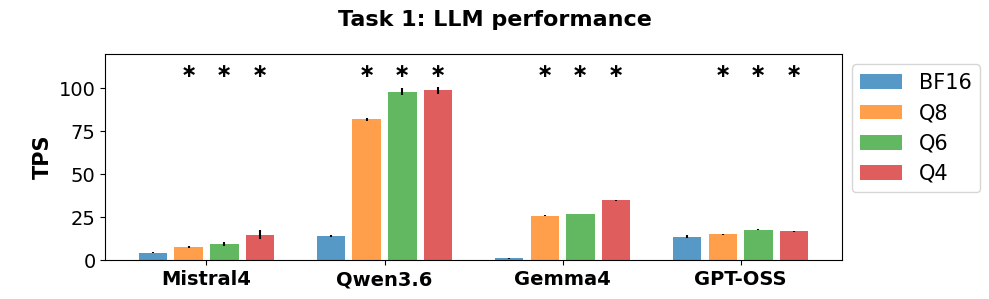

In [227]:
#fig, ax = plt.subplots(2,1, figsize=(10, 5), sharex=True)
fig, ax = plt.subplots(1,1, figsize=(10, 3), sharex=True)
fig.suptitle('Task 1: LLM performance', fontsize=16, fontweight='bold')

plot_data(d_stats=d_stats_task1, stat='tokens_per_second', ax=ax, ylabel='TPS'           , ylim=[0,120], prompt_avg=None, prompt_std=0.0, scale=1, show_legend=True)
#plot_data(d_stats=d_stats_task1, stat='duration_min',      ax=ax[1], ylabel='Duration (min)'  , ylim=[0,130],  prompt_avg=None, prompt_std=0.0, scale=1)

annonate_barplot(ax=ax, df=df_task1, col='tokens_per_second', pval=pval, y=110)
#annonate_barplot(ax=ax[1], df=df_task1, col='duration_min', pval=pval, y=120)



#plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS',            show_legend=True, ylim=[0, 120])
#plot_data_boxplot(df_task2, 'duration_min',      ax=ax[1], ylabel='Duration (min)', show_legend=True, ylim=[0, 130])

#annonate_boxplot(ax[0], df=df_task2, col='tokens_per_second', pval=pval, y=110)
#annonate_boxplot(ax[1], df=df_task2, col='duration_min', pval=pval, y=120)


plt.tight_layout()
plt.show()

In [75]:
_ = utest_intermodel(df=df_task1, col='tokens_per_second', pval_threshold=pval, show_uncorrected_pval=True)

,p-value
"(Mistral4-119B, Qwen3.6-35B)",1.415656e-09
"(Mistral4-119B, gemma-4-31B)",1.415656e-09
"(Mistral4-119B, gpt-oss-120B)",1.415656e-09
"(Qwen3.6-35B, gemma-4-31B)",1.415656e-09
"(Qwen3.6-35B, gpt-oss-120B)",3.281713e-02
"(gemma-4-31B, gpt-oss-120B)",1.415656e-09


Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, Qwen3.6-35B)",1.415656e-09
"(Mistral4-119B, gemma-4-31B)",1.415656e-09
"(Mistral4-119B, gpt-oss-120B)",1.415656e-09
"(Qwen3.6-35B, gemma-4-31B)",1.415656e-09
"(gemma-4-31B, gpt-oss-120B)",1.415656e-09


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


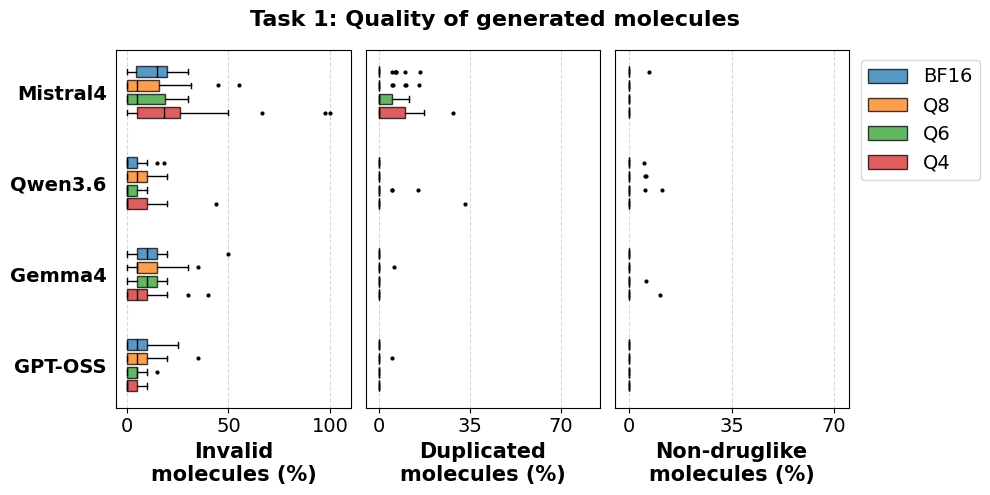

In [234]:

fig, ax = plt.subplots(1,3, figsize=(10, 5), sharey=True)
fig.suptitle('Task 1: Quality of generated molecules', fontsize=16, fontweight='bold')
plot_data_hboxplot(df_task1, 'pct_smi_invalid', ax=ax[0], ylabel='Invalid\nmolecules (%)', xlim=[-5,110], xticks=[0,50,100], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_duplicated', ax=ax[1], ylabel='Duplicated\nmolecules (%)', xlim=[-5,85], xticks=[0,35,70], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_notdruglike', ax=ax[2], ylabel='Non-druglike\nmolecules (%)', xlim=[-5,75], xticks=[0,35,70], scale=100, show_legend=True)

annonate_hboxplot(ax[0], df=df_task1, col='pct_smi_invalid',     pval=pval, x=105)
annonate_hboxplot(ax[1], df=df_task1, col='pct_smi_duplicated',  pval=pval, x=65)
annonate_hboxplot(ax[2], df=df_task1, col='pct_smi_notdruglike', pval=pval, x=65)

plt.tight_layout()
plt.show()

In [77]:
_ = utest_intermodel(df=df_task1, col='pct_smi_invalid', pval_threshold=pval, show_uncorrected_pval=True)

,p-value
"(Mistral4-119B, Qwen3.6-35B)",0.001720
"(Mistral4-119B, gemma-4-31B)",0.346770
"(Mistral4-119B, gpt-oss-120B)",0.033751
"(Qwen3.6-35B, gemma-4-31B)",0.002332
"(Qwen3.6-35B, gpt-oss-120B)",0.130500
"(gemma-4-31B, gpt-oss-120B)",0.068410


Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, Qwen3.6-35B)",0.001720
"(Qwen3.6-35B, gemma-4-31B)",0.002332


In [78]:
_ = utest_intermodel(df=df_task1, col='pct_smi_duplicated', pval_threshold=pval, show_uncorrected_pval=True)

,p-value
"(Mistral4-119B, Qwen3.6-35B)",0.010434
"(Mistral4-119B, gemma-4-31B)",0.010434
"(Mistral4-119B, gpt-oss-120B)",0.010434
"(Qwen3.6-35B, gemma-4-31B)",NaN
"(Qwen3.6-35B, gpt-oss-120B)",NaN
"(gemma-4-31B, gpt-oss-120B)",NaN


Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value


In [79]:
_ = utest_intermodel(df=df_task1, col='pct_smi_notdruglike', pval_threshold=pval, show_uncorrected_pval=True)

,p-value
"(Mistral4-119B, Qwen3.6-35B)",1.000000
"(Mistral4-119B, gemma-4-31B)",0.337055
"(Mistral4-119B, gpt-oss-120B)",0.337055
"(Qwen3.6-35B, gemma-4-31B)",0.337055
"(Qwen3.6-35B, gpt-oss-120B)",0.337055
"(gemma-4-31B, gpt-oss-120B)",NaN


Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(gpt-oss-120B, Q4)",0.003186


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Mistral4-119B, Q8)",1.689323e-03
"(Mistral4-119B, Q6)",4.485638e-20
"(Mistral4-119B, Q4)",3.182942e-06
"(gemma-4-31B, Q6)",1.089755e-04
"(gpt-oss-120B, Q8)",5.212444e-06
"(gpt-oss-120B, Q4)",2.741084e-63


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Mistral4-119B, Q4)",5.960545e-07
"(gemma-4-31B, Q8)",1.565686e-03
"(gemma-4-31B, Q4)",2.964874e-03
"(gpt-oss-120B, Q4)",4.484457e-06


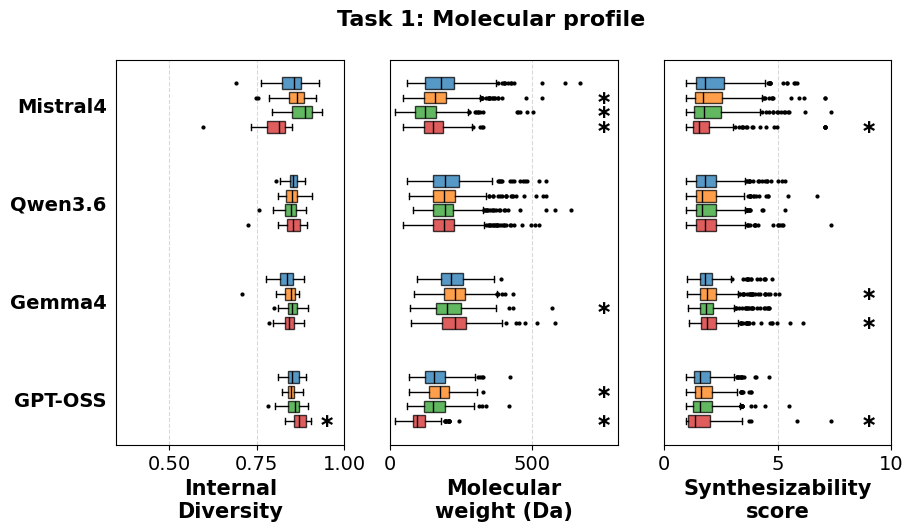

In [229]:
fig, ax = plt.subplots(1,3, figsize=(10, 5), sharey=True)
fig.suptitle('Task 1: Molecular profile', fontsize=16, fontweight='bold')

plot_data_hboxplot(df_task1, 'intdiv', ax=ax[0], ylabel='Internal\nDiversity', show_legend=False, xlim=[0.35, 1.00], prompt=None)
plot_data_hboxplot(df_task1.groupby(['model', 'quantization']).sum()['mw'].reset_index(), 'mw', ax=ax[1], ylabel='Molecular\nweight (Da)', show_legend=False, xlim=[0,800], prompt=None)
plot_data_hboxplot(df_task1.groupby(['model', 'quantization']).sum()['synthesizability'].reset_index(), 'synthesizability', ax=ax[2], ylabel='Synthesizability\nscore', show_legend=False, xlim=[0,10], prompt=None)

annonate_hboxplot(ax[0], df=df_task1, col='intdiv', pval=pval, x=0.95)
annonate_hboxplot(ax[1], df=df_task1.groupby(['model', 'quantization']).sum()['mw'].reset_index(), col='mw', pval=pval, x=750)
annonate_hboxplot(ax[2], df=df_task1.groupby(['model', 'quantization']).sum()['synthesizability'].reset_index(), col='synthesizability', pval=pval, x=9)



In [81]:
_ = utest_intermodel(df=df_task1, col='intdiv', pval_threshold=pval, show_uncorrected_pval=True)

,p-value
"(Mistral4-119B, Qwen3.6-35B)",1.000000
"(Mistral4-119B, gemma-4-31B)",0.138408
"(Mistral4-119B, gpt-oss-120B)",0.991495
"(Qwen3.6-35B, gemma-4-31B)",0.020947
"(Qwen3.6-35B, gpt-oss-120B)",0.627626
"(gemma-4-31B, gpt-oss-120B)",0.045663


Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value


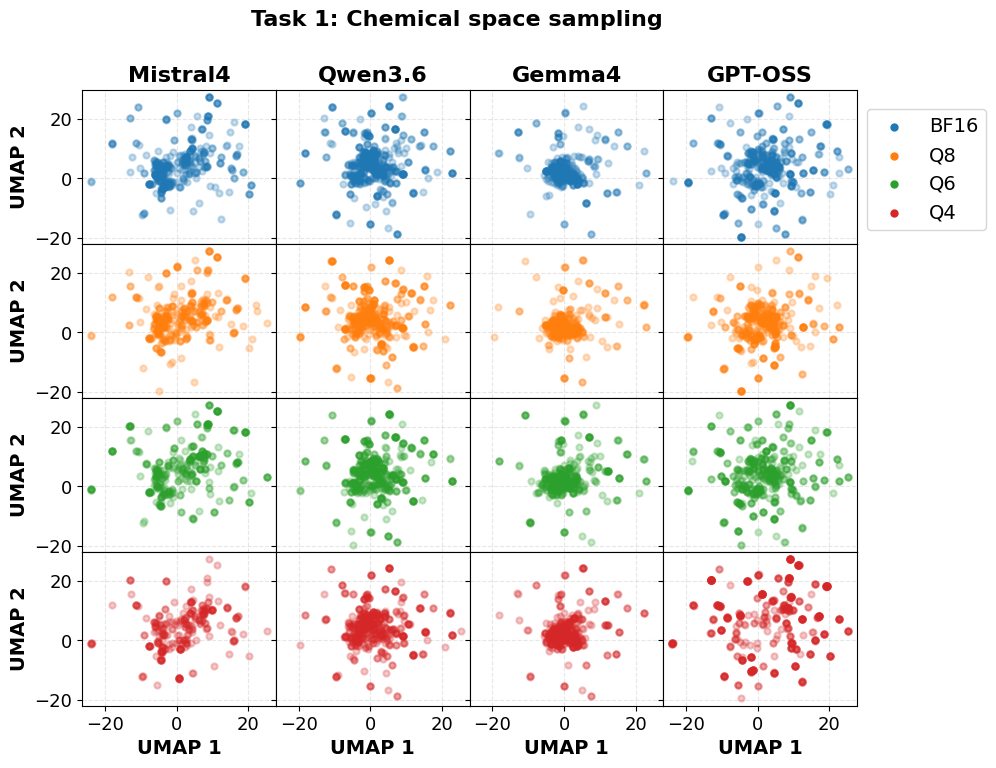

In [221]:
plot_umap_grid(df_task1_umap_all, prompt=False, title='Task 1: Chemical space sampling')

# **FIGURAS** - TASK2

Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Mistral4-119B, Q8)",1.415656e-09
"(Mistral4-119B, Q6)",1.415656e-09
"(Mistral4-119B, Q4)",1.415656e-09
"(Qwen3.6-35B, Q8)",1.415656e-09
"(Qwen3.6-35B, Q6)",1.415656e-09
"(Qwen3.6-35B, Q4)",1.415656e-09
"(gemma-4-31B, Q8)",1.415656e-09
"(gemma-4-31B, Q6)",1.415656e-09
"(gemma-4-31B, Q4)",1.415656e-09
"(gpt-oss-120B, Q8)",2.898035e-09


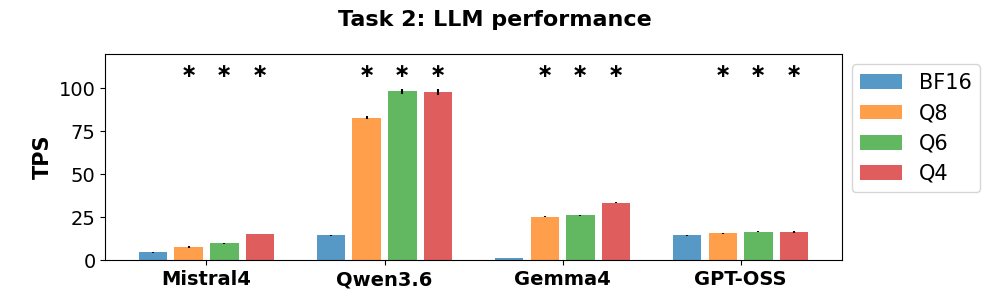

In [230]:
#fig, ax = plt.subplots(2,1, figsize=(10, 5), sharex=True)
fig, ax = plt.subplots(1,1, figsize=(10, 3), sharex=True)
fig.suptitle('Task 2: LLM performance', fontsize=16, fontweight='bold')

plot_data(d_stats=d_stats_task2, stat='tokens_per_second', ax=ax, ylabel='TPS'           , ylim=[0,120], prompt_avg=None, prompt_std=0.0, scale=1, show_legend=True)
#plot_data(d_stats=d_stats_task2, stat='duration_min',      ax=ax[1], ylabel='Duration (min)'  , ylim=[0,130],  prompt_avg=None, prompt_std=0.0, scale=1)

annonate_barplot(ax=ax, df=df_task2, col='tokens_per_second', pval=pval, y=110)
#annonate_barplot(ax=ax[1], df=df_task2, col='duration_min', pval=pval, y=120)



#plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS',            show_legend=True, ylim=[0, 120])
#plot_data_boxplot(df_task2, 'duration_min',      ax=ax[1], ylabel='Duration (min)', show_legend=True, ylim=[0, 130])

#annonate_boxplot(ax[0], df=df_task2, col='tokens_per_second', pval=pval, y=110)
#annonate_boxplot(ax[1], df=df_task2, col='duration_min', pval=pval, y=120)


plt.tight_layout()
plt.show()

In [86]:
_ = utest_intermodel(df=df_task2, col='tokens_per_second', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, Qwen3.6-35B)",1.415656e-09
"(Mistral4-119B, gemma-4-31B)",1.415656e-09
"(Mistral4-119B, gpt-oss-120B)",1.415656e-09
"(Qwen3.6-35B, gemma-4-31B)",1.415656e-09
"(gemma-4-31B, gpt-oss-120B)",1.415656e-09


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(gpt-oss-120B, Q4)",0.000116


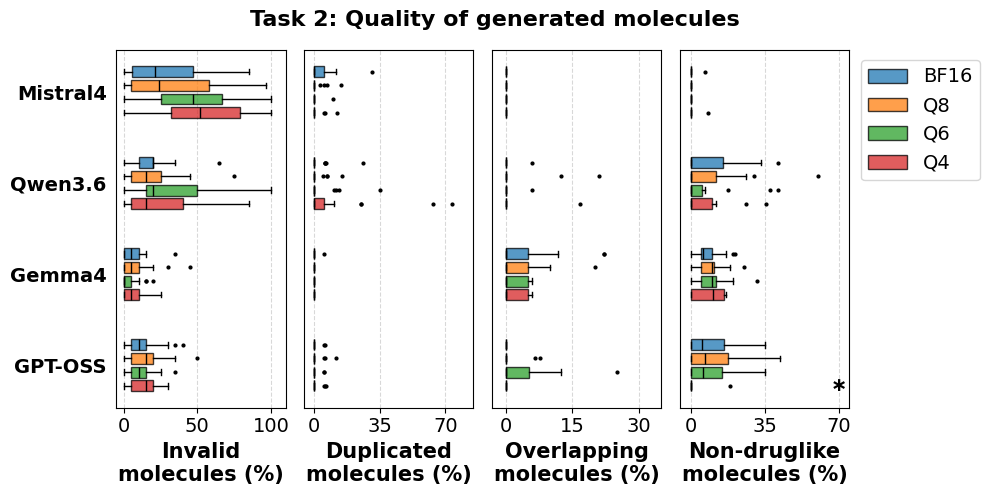

In [233]:
# This function returns a dictionary with the coordinates of each group (which is used to add * to indicate statistical significance)

fig, ax = plt.subplots(1,4, figsize=(10, 5), sharey=True)
fig.suptitle('Task 2: Quality of generated molecules', fontsize=16, fontweight='bold')
plot_data_hboxplot(df_task2, 'pct_smi_invalid',     ax=ax[0], ylabel='Invalid\nmolecules (%)',      xlim=[-5,110], xticks=[0,50,100], scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_duplicated',  ax=ax[1], ylabel='Duplicated\nmolecules (%)',   xlim=[-5,85],  xticks=[0,35,70],  scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_overlap',     ax=ax[2], ylabel='Overlapping\nmolecules (%)',  xlim=[-3,35],  xticks=[0,15,30],  scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_notdruglike', ax=ax[3], ylabel='Non-druglike\nmolecules (%)', xlim=[-5,75],  xticks=[0,35,70],  scale=100, show_legend=True)

annonate_hboxplot(ax[0], df=df_task2, col='pct_smi_invalid',     pval=pval, x=105)
annonate_hboxplot(ax[1], df=df_task2, col='pct_smi_duplicated',  pval=pval,  x=70)
annonate_hboxplot(ax[2], df=df_task2, col='pct_smi_overlap',     pval=pval,  x=30)
annonate_hboxplot(ax[3], df=df_task2, col='pct_smi_notdruglike', pval=pval,  x=70)

plt.tight_layout()
plt.show()

In [88]:
_ = utest_intermodel(df=df_task2, col='pct_smi_invalid', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, gemma-4-31B)",0.000127
"(Qwen3.6-35B, gemma-4-31B)",0.000055
"(gemma-4-31B, gpt-oss-120B)",0.005917


In [89]:
_ = utest_intermodel(df=df_task2, col='pct_smi_duplicated', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value


In [90]:
_ = utest_intermodel(df=df_task2, col='pct_smi_overlap', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, gemma-4-31B)",0.001163
"(Qwen3.6-35B, gemma-4-31B)",0.006172
"(gemma-4-31B, gpt-oss-120B)",0.001163


In [91]:
_ = utest_intermodel(df=df_task2, col='pct_smi_notdruglike', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, Qwen3.6-35B)",3.540785e-04
"(Mistral4-119B, gemma-4-31B)",7.184082e-07
"(Mistral4-119B, gpt-oss-120B)",6.386868e-05


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(gpt-oss-120B, Q4)",0.00138


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Mistral4-119B, Q6)",2.170191e-09
"(gpt-oss-120B, Q4)",5.455106e-81


Bonferroni correction: pval<0.0500 -> pval<0.0042 (12 tests)


,p-value
"(Qwen3.6-35B, Q4)",9.162292e-04
"(gpt-oss-120B, Q4)",5.842196e-31


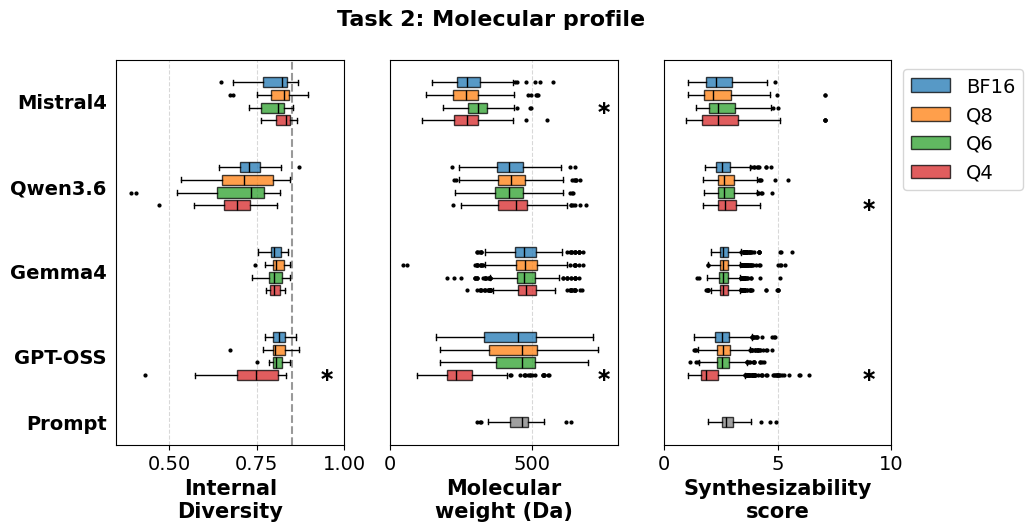

In [232]:
fig, ax = plt.subplots(1,3, figsize=(10, 5), sharey=True)
fig.suptitle('Task 2: Molecular profile', fontsize=16, fontweight='bold')

plot_data_hboxplot(df_task2, 'intdiv', ax=ax[0], ylabel='Internal\nDiversity', show_legend=False, xlim=[0.35, 1.00], prompt=d_prompt['intdiv'])
plot_data_hboxplot(df_task2.groupby(['model', 'quantization']).sum()['mw'].reset_index(), 'mw', ax=ax[1], ylabel='Molecular\nweight (Da)', show_legend=False, xlim=[0,800], prompt=d_prompt['mw'])
plot_data_hboxplot(df_task2.groupby(['model', 'quantization']).sum()['synthesizability'].reset_index(), 'synthesizability', ax=ax[2], ylabel='Synthesizability\nscore', show_legend=True, xlim=[0,10], prompt=d_prompt['synthesizability'])

annonate_hboxplot(ax[0], df=df_task2, col='intdiv', pval=pval, x=0.95)
annonate_hboxplot(ax[1], df=df_task2.groupby(['model', 'quantization']).sum()['mw'].reset_index(), col='mw', pval=pval, x=750)
annonate_hboxplot(ax[2], df=df_task2.groupby(['model', 'quantization']).sum()['synthesizability'].reset_index(), col='synthesizability', pval=pval, x=9)



In [93]:
_ = utest_intermodel(df=df_task2, col='intdiv', pval_threshold=pval, show_uncorrected_pval=False)

Bonferroni correction: pval<0.0500 -> pval<0.0083 (6 tests)


,p-value
"(Mistral4-119B, Qwen3.6-35B)",0.000568
"(Qwen3.6-35B, gemma-4-31B)",0.000005
"(Qwen3.6-35B, gpt-oss-120B)",0.000001


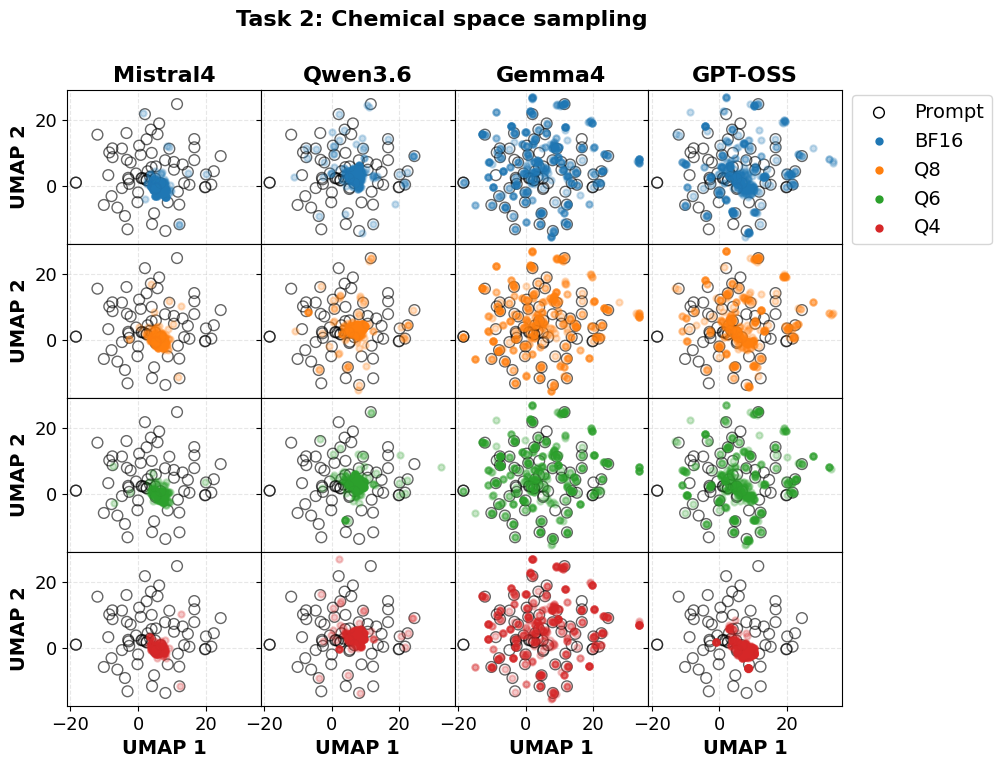

In [223]:
plot_umap_grid(df_task2_umap_all, prompt=True, title='Task 2: Chemical space sampling')

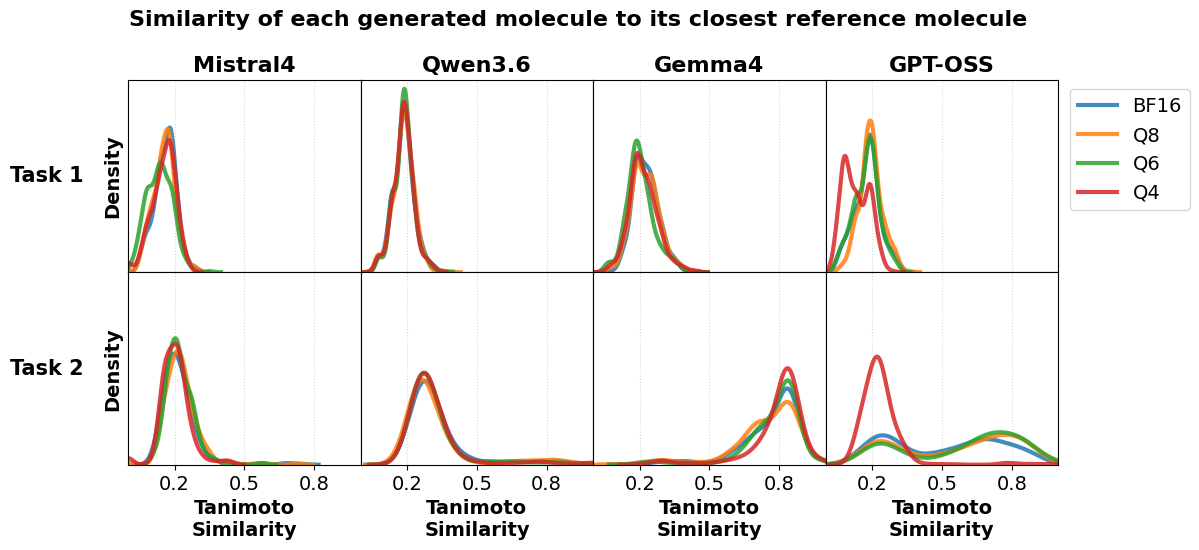

In [218]:
fig, ax = plt.subplots(2, 4, figsize=(12, 5), sharey=True, sharex=True)
fig.suptitle('Similarity of each generated molecule to its closest reference molecule\n\n', fontsize=16, fontweight='bold', y=1.02)

i=0
for model,label in zip(lst_models, lst_models_labels):
    if i==len(lst_models)-1:
        show_legend = True
    else:
        show_legend = False
        
    plot_data_kde(df_task1, model, label, stat='sim max', ax=ax[0][i], show_legend=show_legend, style='-')
    plot_data_kde(df_task2, model, label, stat='sim max', ax=ax[1][i], show_legend=False, style='-')
    ax[0][i].set_title('\n'+label, loc='center', fontsize=16, fontweight='bold')#, pad=4)

    i+=1

ax[0,0].yaxis.get_label().set_visible(True)
ax[1,0].yaxis.get_label().set_visible(True)

ax[0, 0].annotate('Task 1', xy=(-0.35, 0.5), xycoords='axes fraction',
                  fontsize=15, fontweight='bold', rotation=0, ha='center', va='center')

ax[1, 0].annotate('Task 2', xy=(-0.35, 0.5), xycoords='axes fraction',
                  fontsize=15, fontweight='bold', rotation=0, ha='center', va='center')

#plt.tight_layout()
fig.subplots_adjust(wspace=0.0, hspace=0)

---

---